# Interpolate coarsened ERA5 reanalysis to balloon location

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
import matplotlib.cm
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
import datetime
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from scipy.stats import norm
from scipy.stats import skew
from scipy.stats import kurtosis
import netCDF4 as nc

from tqdm.notebook import tqdm
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

warnings.simplefilter("ignore")

### Load in the coarsened ERA5 reanalysis

In [2]:
# Load in the reanalysis coordinates
file_path = str('temperature_coarse.nc') # use any of the reanalysis gridded variables
dataset = nc.Dataset(file_path)
lat_grid = np.array(dataset.variables['latitude']) # (deg. N)
lon_grid = np.array(dataset.variables['longitude']) # (deg. E)
pressure = np.array(dataset.variables['pressure']) # (hPa)
time_reanalysis = np.array(dataset.variables['time'])
time_reanalysis_start = pd.Timestamp('2019-11-01 00:00:00') # can be found in dataset.variables
dt_reanalysis = pd.Timedelta(1,'hours') # compare dt to the info in dataset.variables
nlat_grid = lat_grid.size
nlon_grid = lon_grid.size
# The time index when the reanalysis switches from the C0 to the C1 balloons ('time' has units of hours)
ind_campaign_switch = (pd.Timestamp('2021-09-01 00:00:00') - time_reanalysis_start)/pd.Timedelta(1,'hours')
ind_campaign_switch = time_reanalysis[time_reanalysis < ind_campaign_switch].size
# The reduction in the time index used later when finding the reanalysis time step
delta_ind = time_reanalysis[ind_campaign_switch] - \
            (time_reanalysis[ind_campaign_switch-1] + dt_reanalysis/pd.Timedelta(1,'hours'))
delta_ind = int(delta_ind/(dt_reanalysis/pd.Timedelta(1,'hours')))

# Load in the reanalysis zonal and meridional winds and calculate the wind speed
file_path = str('temperature_coarse.nc')
dataset = nc.Dataset(file_path)
temperature_reanalysis = np.array(dataset.variables['__xarray_dataarray_variable__']) # (m/s)
file_path = str('N2_coarse.nc')
dataset = nc.Dataset(file_path)
N2_reanalysis = np.array(dataset.variables['__xarray_dataarray_variable__']) # (m/s)

### Load in each flight, interpolate the reanalysis to its pressure, and save

Flight C0_01_STR1
Flight C0_02_STR2
Flight C0_03_TTL3
Flight C0_04_TTL1
Flight C0_05_TTL2
Flight C0_06_STR1
Flight C0_07_STR2
Flight C0_08_STR2
Flight C1_01_TTL5
Flight C1_02_STR1
Flight C1_03_TTL4
Flight C1_04_STR2
Flight C1_05_TTL3
Flight C1_06_TTL5
Flight C1_07_TTL4
Flight C1_08_STR1
Flight C1_09_STR2
Flight C1_10_TTL3
Flight C1_11_TTL1
Flight C1_12_STR4
Flight C1_13_STR1
Flight C1_15_TTL4
Flight C1_16_TTL5
Flight C1_17_TTL3


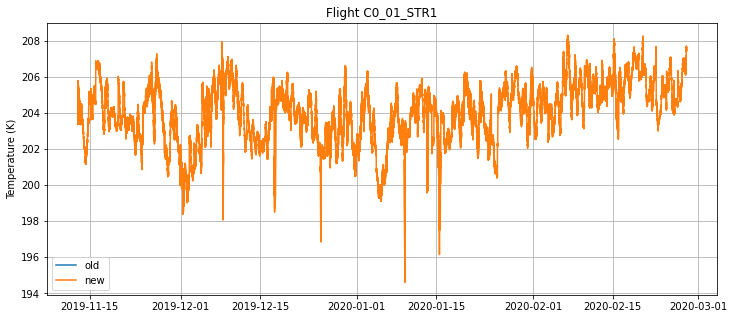

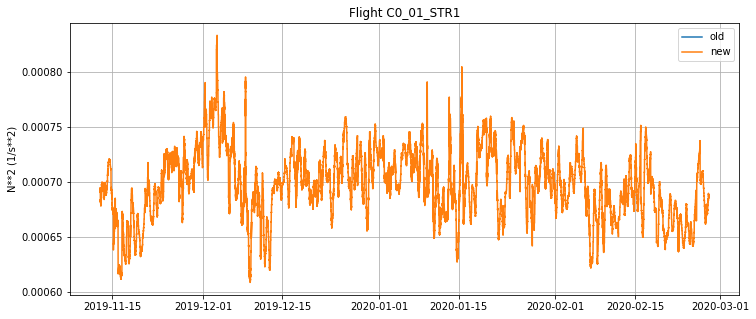

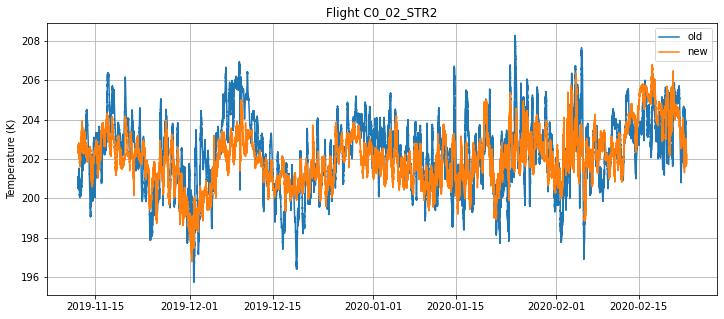

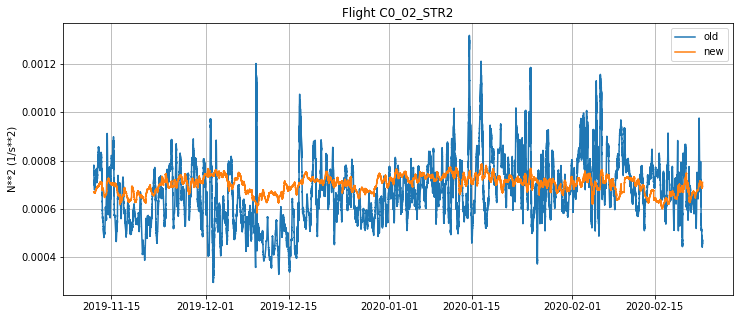

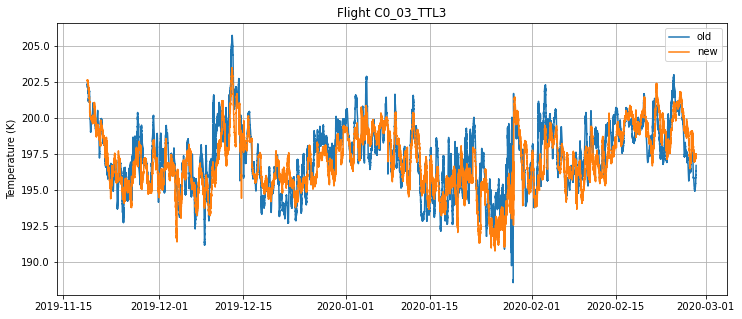

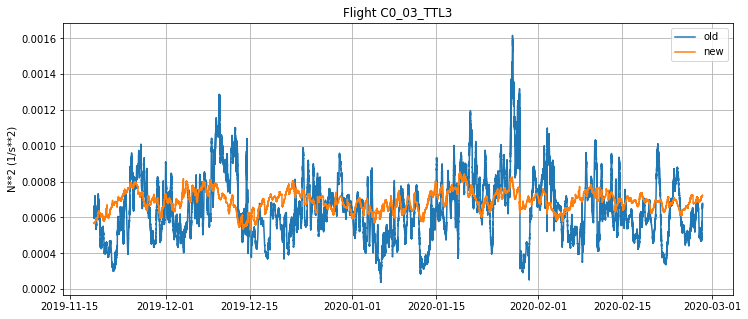

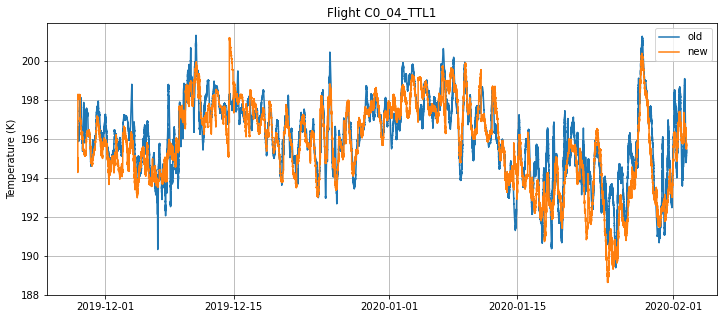

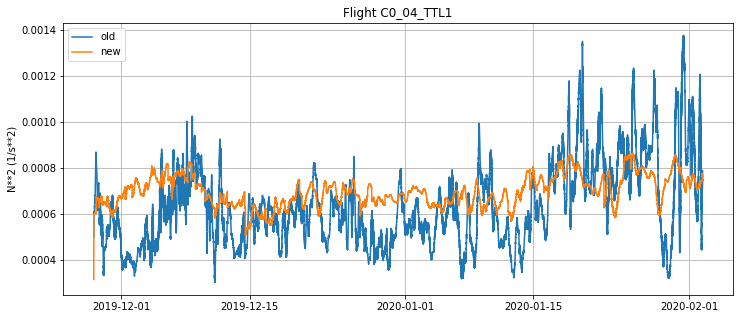

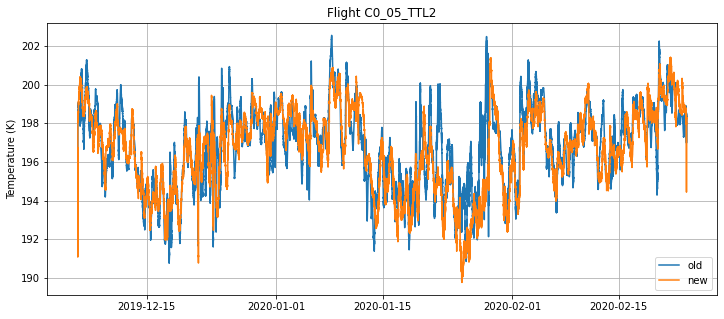

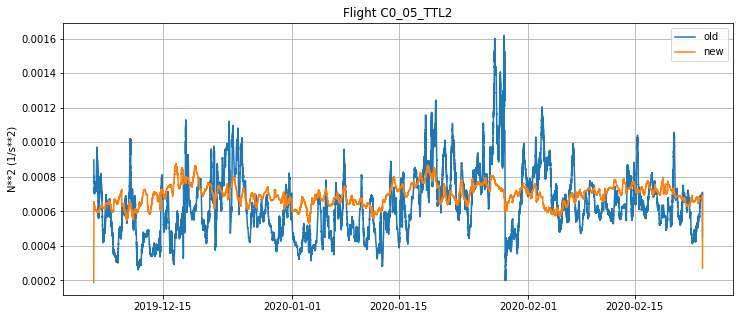

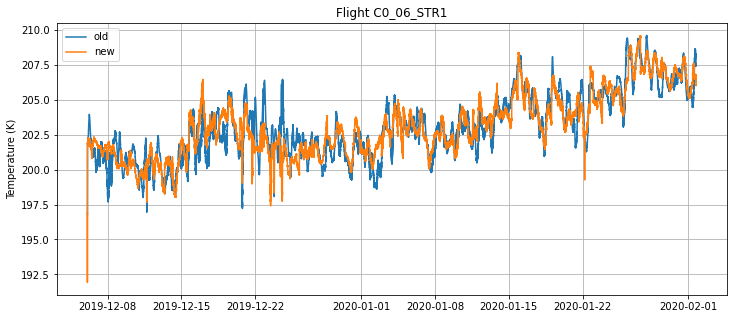

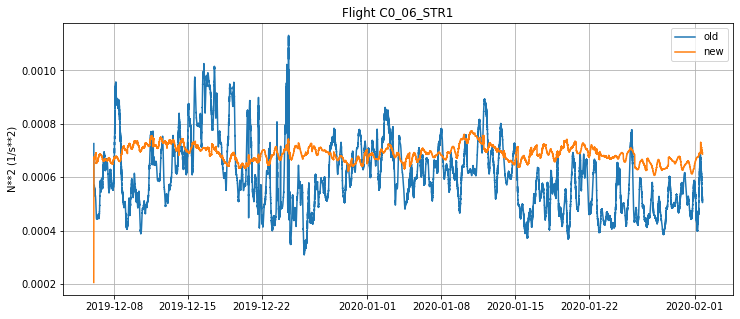

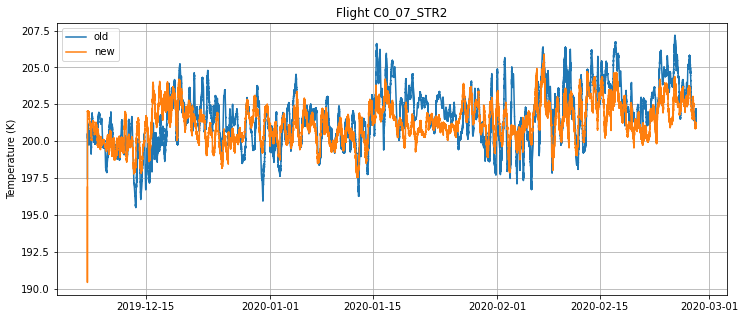

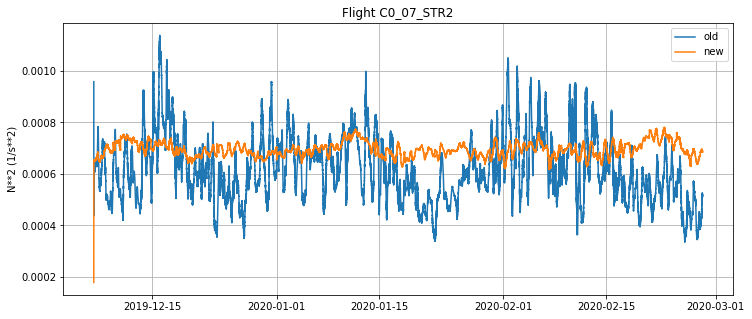

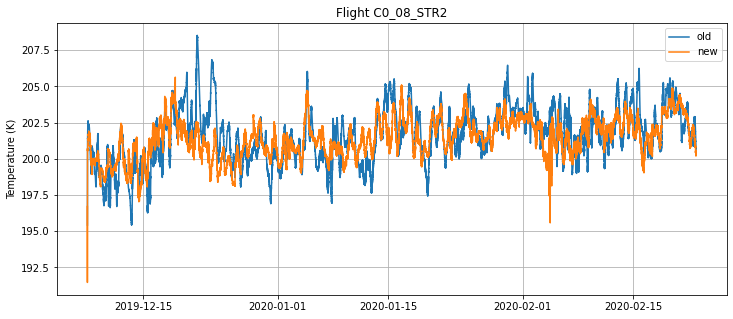

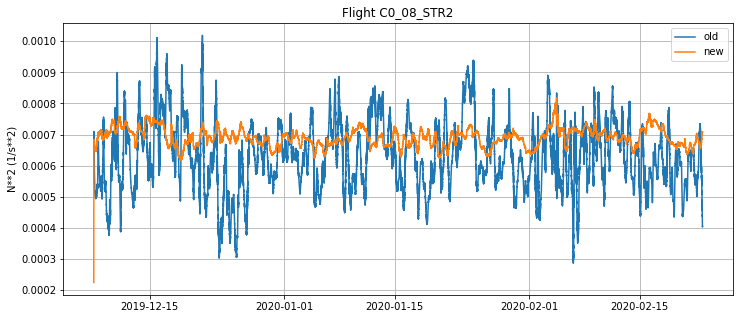

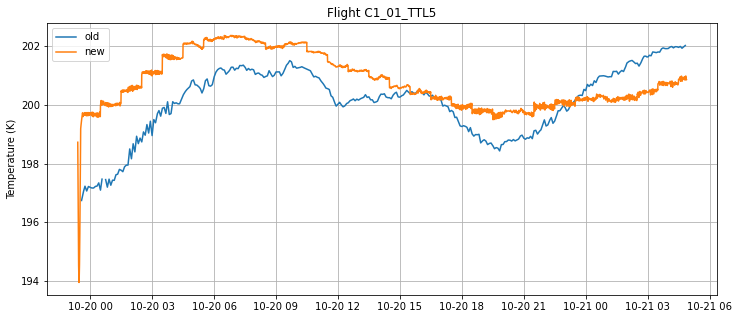

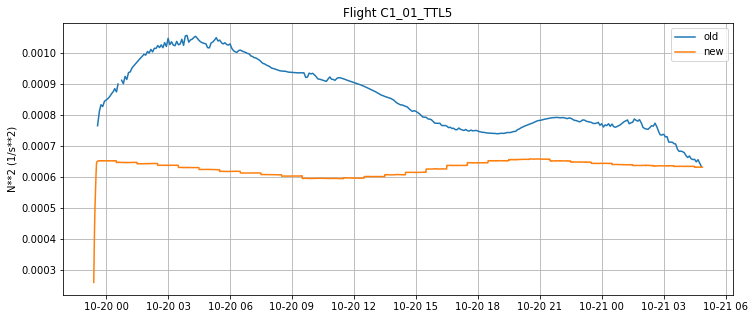

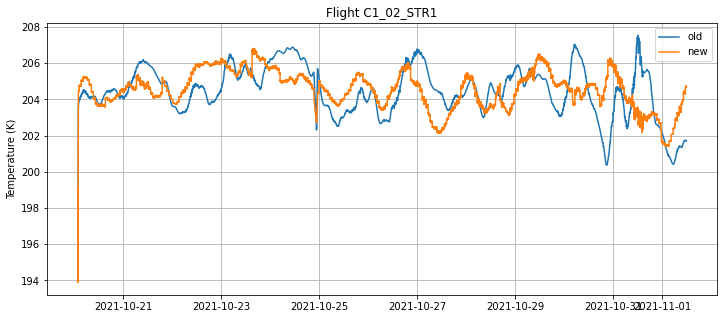

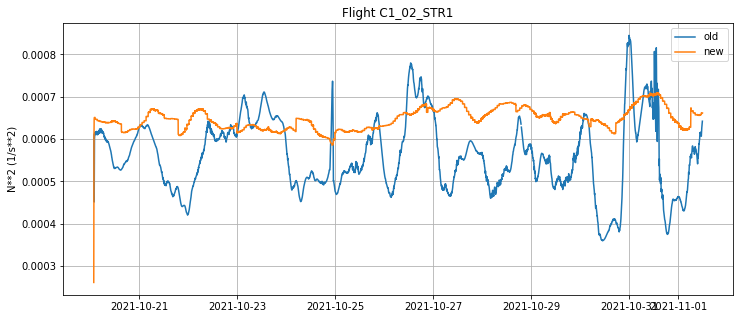

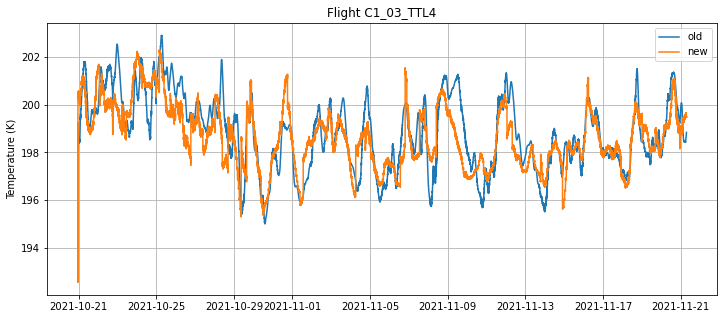

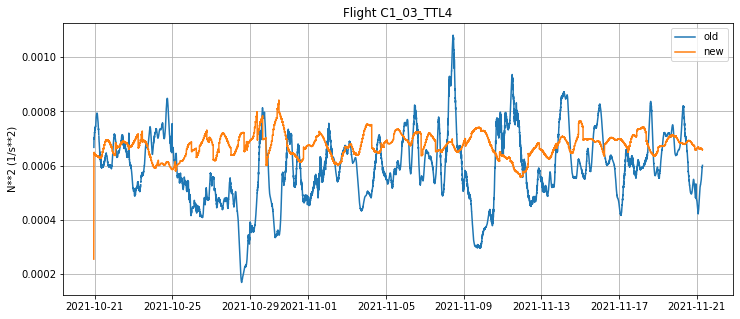

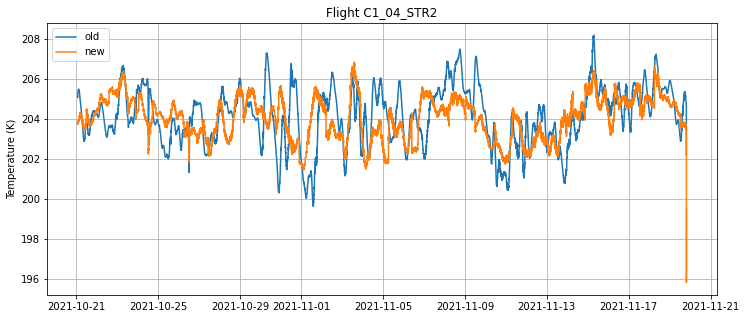

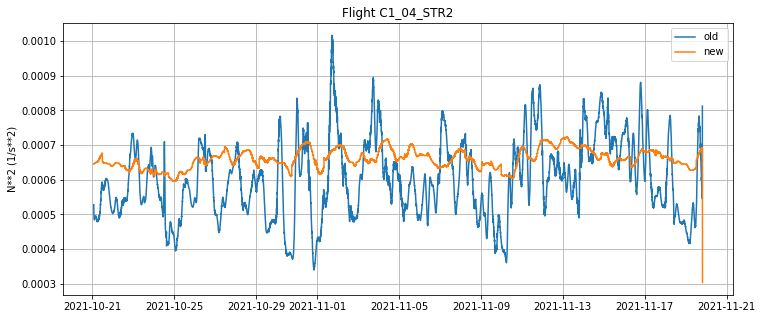

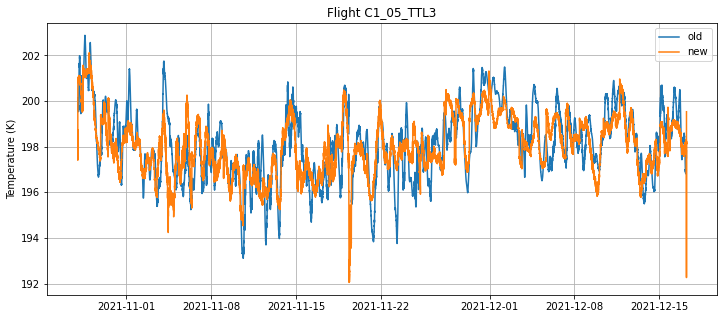

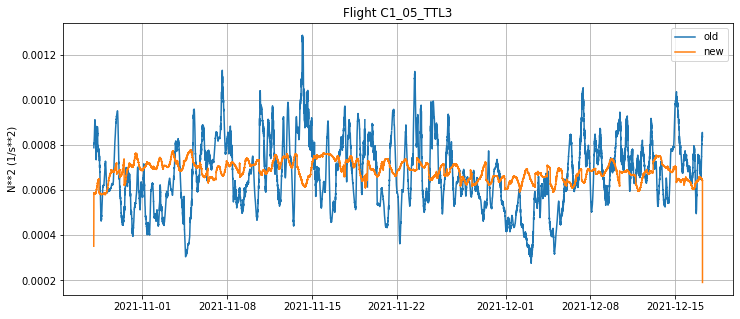

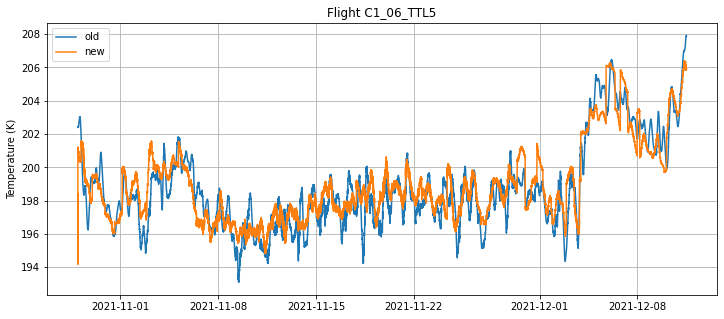

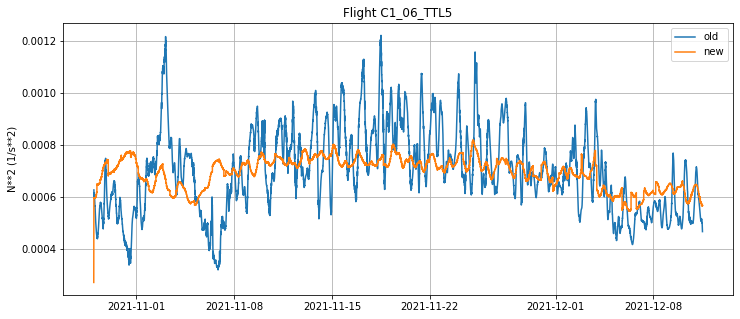

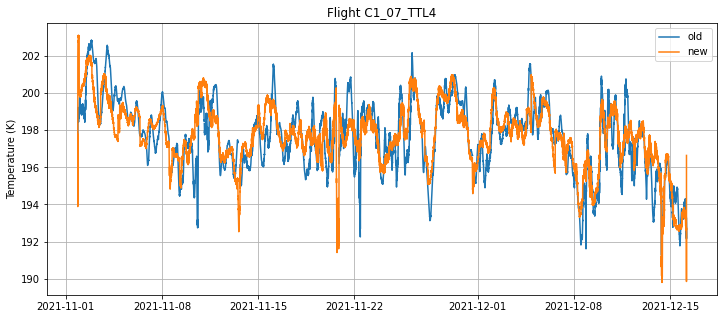

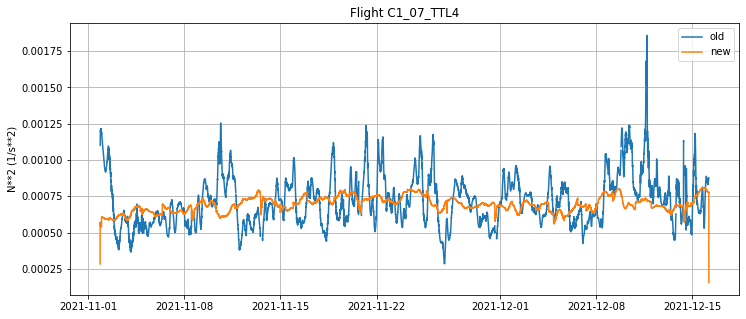

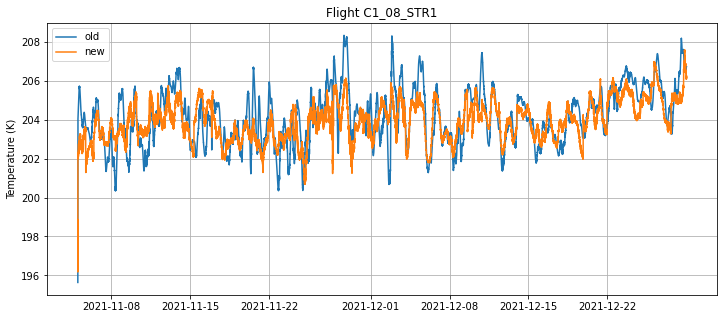

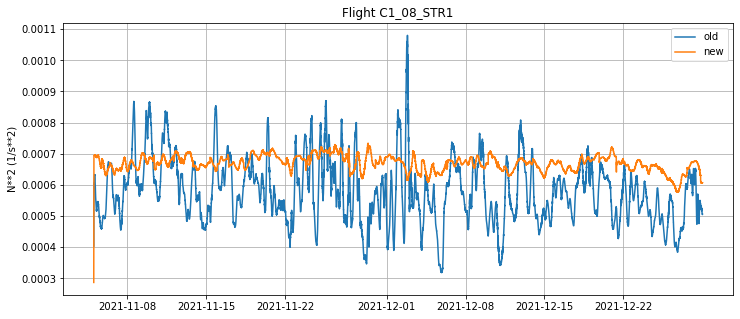

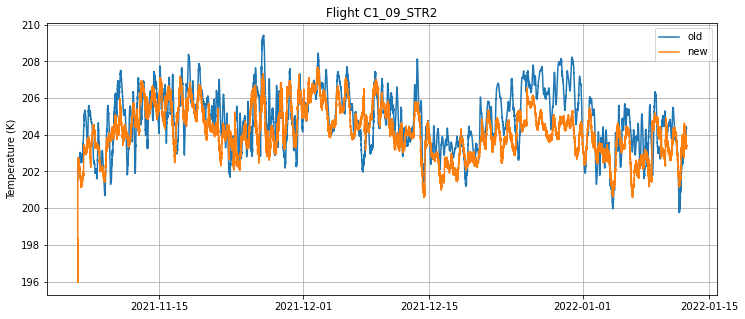

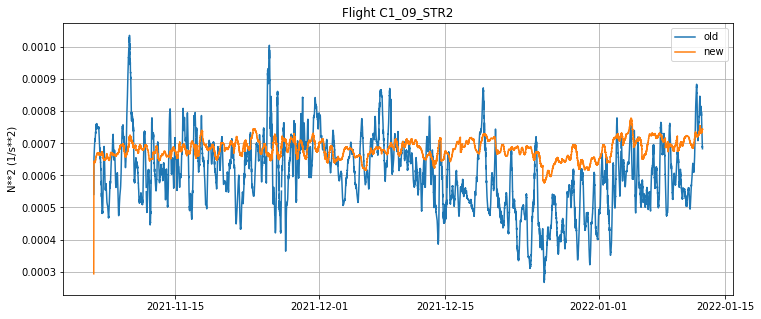

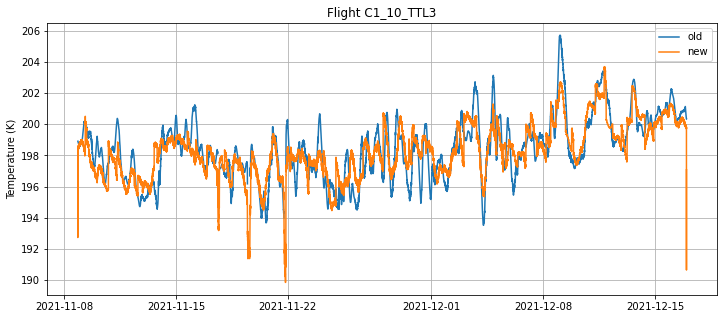

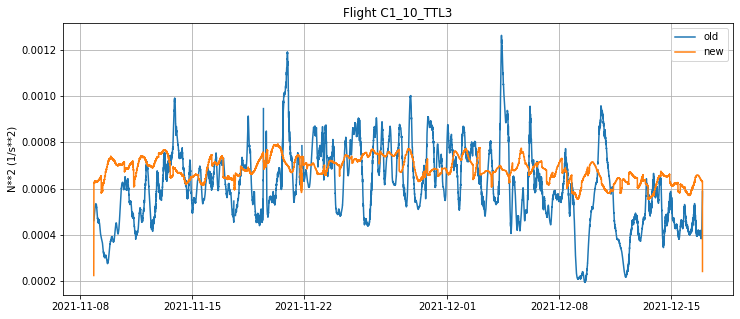

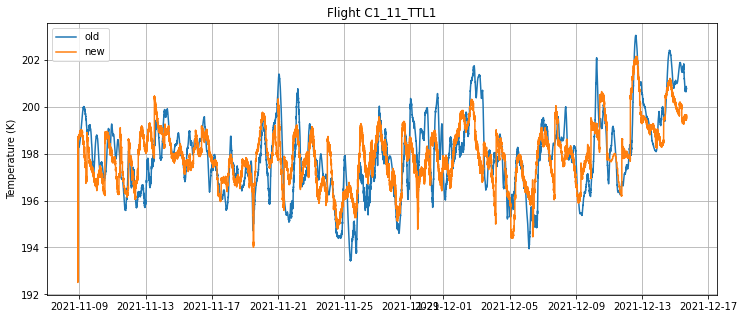

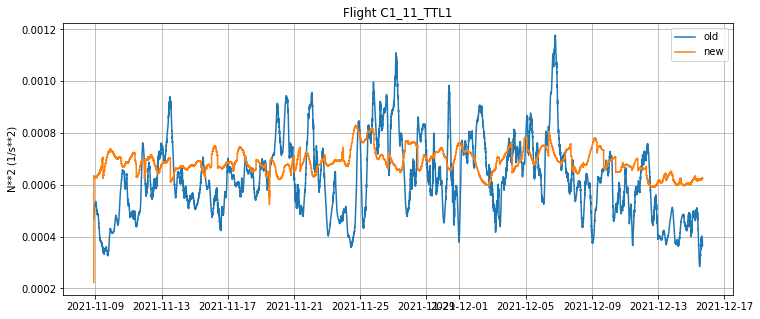

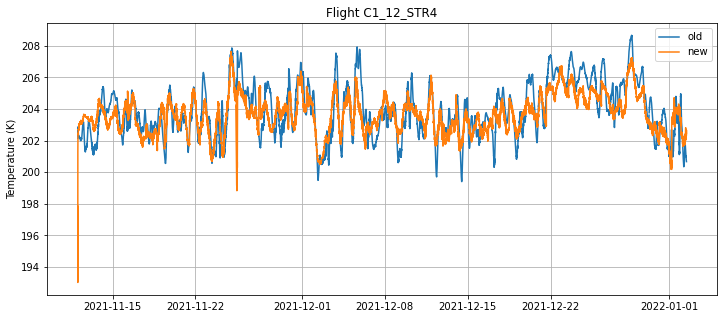

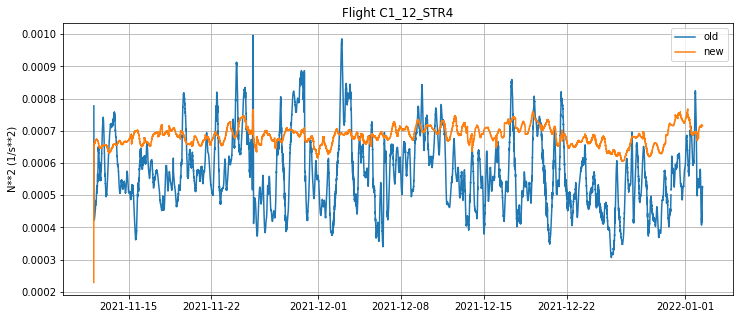

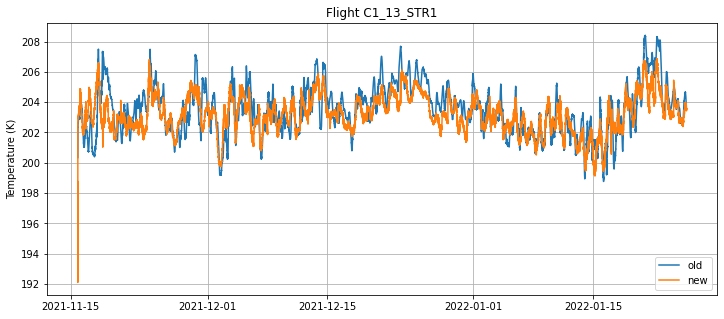

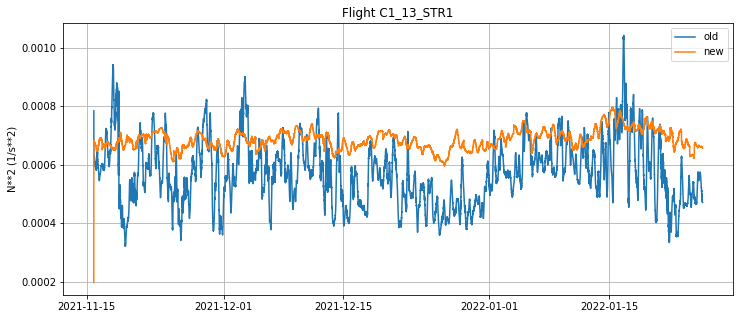

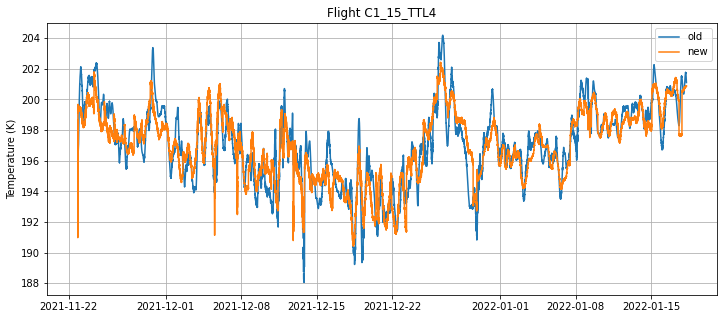

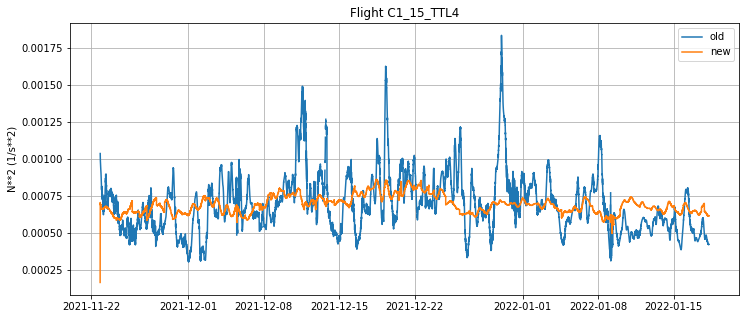

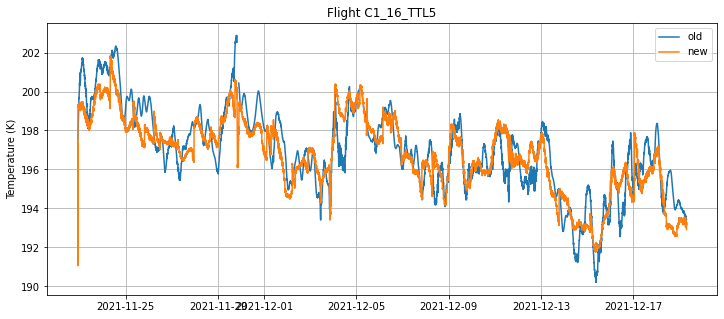

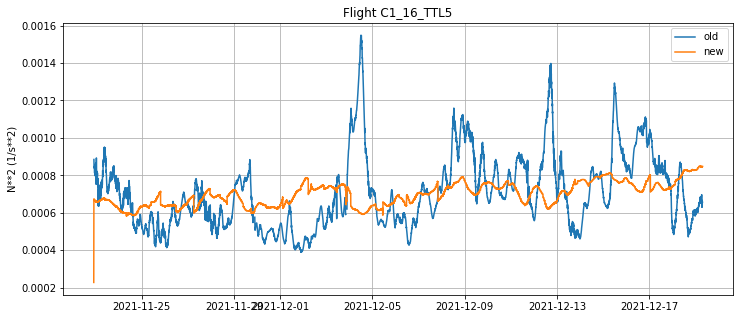

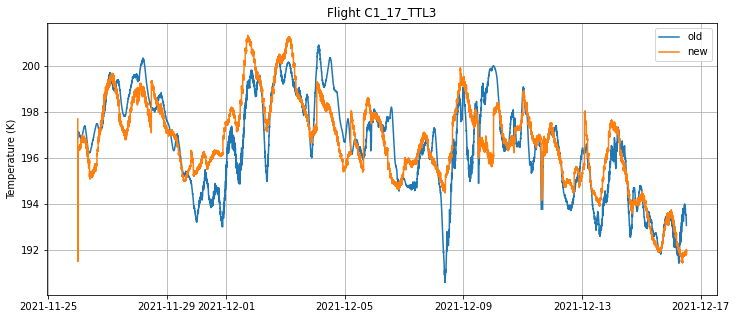

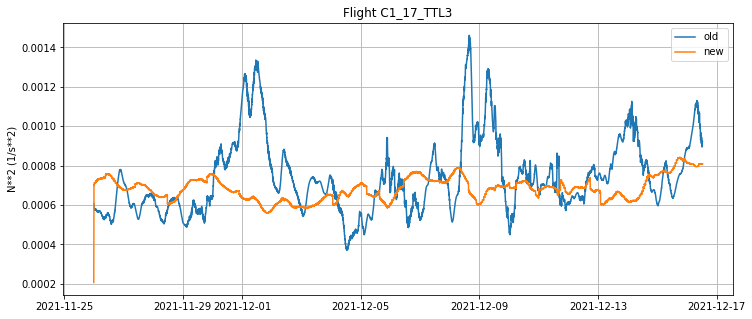

In [3]:
file_paths = np.array(['ST2_C0_01_STR1_tsen.nc',
                       '../../strateole2_from_aurelien/ST2_C0_02_STR2_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_03_TTL3_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_04_TTL1_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_05_TTL2_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_06_STR1_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_07_STR2_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C0_08_STR2_tsen_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_01_TTL5_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_02_STR1_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_03_TTL4_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_04_STR2_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_05_TTL3_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_06_TTL5_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_07_TTL4_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_08_STR1_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_09_STR2_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_10_TTL3_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_11_TTL1_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_12_STR4_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_13_STR1_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_15_TTL4_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_16_TTL5_TSEN_v01_with_ERA5.nc',
                       '../../strateole2_from_aurelien/ST2_C1_17_TTL3_TSEN_v01_with_ERA5.nc'])
flight_ids = np.array(['C0_01_STR1','C0_02_STR2','C0_03_TTL3','C0_04_TTL1',
                       'C0_05_TTL2','C0_06_STR1','C0_07_STR2','C0_08_STR2',
                       'C1_01_TTL5','C1_02_STR1','C1_03_TTL4','C1_04_STR2',
                       'C1_05_TTL3','C1_06_TTL5','C1_07_TTL4','C1_08_STR1',
                       'C1_09_STR2','C1_10_TTL3','C1_11_TTL1','C1_12_STR4',
                       'C1_13_STR1','C1_15_TTL4','C1_16_TTL5','C1_17_TTL3'])
time_start_flag = np.array([1,1,1,1,1,1,1,1,
                            0,0,0,0,0,0,0,0,
                            0,0,0,0,0,0,0,0])
n_flights = file_paths.size

for j in np.arange(n_flights):
    
    print('Flight', flight_ids[j])
    
    # Load in the Loon data and the lat/lon grid from the coarsened ERA5 data
    dataset = nc.Dataset(file_paths[j])
    flight = pd.DataFrame()
    flight['u'] = np.array(dataset.variables['u'])
    flight['v'] = np.array(dataset.variables['v'])
    flight['altitude'] = np.array(dataset.variables['alt'])
    flight['pressure'] = np.array(dataset.variables['pressure'])
    flight['latitude'] = np.array(dataset.variables['lat'])
    flight['longitude'] = np.array(dataset.variables['lon'])
    flight['superpressure'] = np.array(dataset.variables['superpressure'])
    flight['flight_id'] = flight_ids[j]
    if flight_ids[j] != 'C0_01_STR1':
        flight['T_ERA5'] = np.array(dataset.variables['T_ERA5'])
        flight['N2_ERA5'] = np.array(dataset.variables['N2_ERA5'])
    else:
        flight['T_ERA5'] = np.nan
        flight['N2_ERA5'] = np.nan
    
    # Get the time in the right format
    if time_start_flag[j] == 0:
        time_start = pd.Timestamp('2019-01-01 00:00:00')
    elif time_start_flag[j] == 1:
        time_start = pd.Timestamp('2019-11-01 00:00:00')
    time = pd.to_timedelta(np.array(dataset.variables['time']), 's')
    flight['time'] = time_start + time
    
    # Delete data where the latitude is NaN
    flight = flight[np.isnan(flight.latitude) == False]
    # Start the flight when the ambient pressure drops below 125 hPa (the highest pressure level with N2)
    flight = flight[flight.pressure < 125]
    flight = flight.sort_values(by=['time']).reset_index(drop=True)
    
    # Assign "grid cell numbers" and "time indices" to each balloon data point corresponding to 
    # a grid cell and time step in the coarsened reanalysis
    time_ind = np.array((flight.time - time_reanalysis_start)/dt_reanalysis)
    #time_ind[time_ind > (time_reanalysis.size - 1)] = time_reanalysis.size - 1
    time_ind[time_ind > ind_campaign_switch] = time_ind[time_ind > ind_campaign_switch] - delta_ind
    flight['time_ind'] = np.round(time_ind)

    # Create a cell "number" for each grid cell, essentially making each cell its own region
    grid_cell_numbers = np.arange(nlat_grid*nlon_grid).reshape(nlat_grid,nlon_grid)
    grid_cell_numbers = grid_cell_numbers.astype(float)

    # Make a list of each grid cell's latitude and longitude
    [temp_lat, temp_lon] = np.meshgrid(lat_grid, lon_grid)
    temp_lat = np.reshape(temp_lat, nlat_grid*nlon_grid)
    temp_lon = np.reshape(temp_lon, nlat_grid*nlon_grid)

    # Apply a cell number to each GW packet
    data_lat = np.array(flight.latitude)
    data_lon = np.array(flight.longitude)
    temp = np.reshape(np.transpose(grid_cell_numbers), nlat_grid*nlon_grid)
    f = interpolate.NearestNDInterpolator((temp_lat,temp_lon),temp)
    # this is how 2D interpolation is done from a grid to a list of points:
    data_cellnum = [float(f(*p)) for p in zip(data_lat, data_lon)]
    data_cellnum = np.round(np.array(data_cellnum)) # round to the region's integer value
    flight['grid_cell_number'] = data_cellnum
    
    # Set up the interpolated fields
    N = flight.time.size
    n_pressure = pressure.size
    grid_cell_numbers_tiled = np.tile(grid_cell_numbers,(n_pressure,1,1))
    
    # Do the interpolation
    T_ERA5 = np.nan*np.ones(shape=(N))
    N2_ERA5 = np.nan*np.ones(shape=(N))
    for i in np.arange(N):
        
        # Find the profiles at this time step
        ind = int(flight.time_ind.iloc[i])
        grid_cell = flight.grid_cell_number.iloc[i]
        temp = temperature_reanalysis[ind,:,:,:]
        T_profile = temp[grid_cell_numbers_tiled == grid_cell]
        temp = N2_reanalysis[ind,:,:,:]
        N2_profile = temp[grid_cell_numbers_tiled == grid_cell]
        
        # Interpolate the profiles to the balloon's ambient pressure,
        # using cubic interpolation.
        pressure_T = pressure[np.isnan(T_profile) == False]
        T_profile = T_profile[np.isnan(T_profile) == False]
        pressure_N2 = pressure[np.isnan(N2_profile) == False]
        N2_profile = N2_profile[np.isnan(N2_profile) == False]
        f = interpolate.PchipInterpolator(np.flip(pressure_T), np.flip(T_profile))
        T_ERA5[i] = f(flight.pressure.iloc[i])
        f = interpolate.PchipInterpolator(np.flip(pressure_N2), np.flip(N2_profile))
        N2_ERA5[i] = f(flight.pressure.iloc[i])
    
    flight['T_ERA5_old'] = flight.T_ERA5
    flight['N2_ERA5_old'] = flight.N2_ERA5
    flight['T_ERA5'] = T_ERA5
    flight['N2_ERA5'] = N2_ERA5
    
    # Plot
    plt.figure(figsize=(12,5))
    plt.plot(flight.time,flight.T_ERA5_old)
    plt.plot(flight.time,flight.T_ERA5)
    plt.grid()
    plt.title(f'Flight {flight_ids[j]}')
    plt.ylabel(f'Temperature (K)')
    plt.legend(['old','new']);
    
    plt.figure(figsize=(12,5))
    plt.plot(flight.time,flight.N2_ERA5_old)
    plt.plot(flight.time,flight.N2_ERA5)
    plt.grid()
    plt.title(f'Flight {flight_ids[j]}')
    plt.ylabel(f'N**2 (1/s**2)')
    plt.legend(['old','new']);
    
    # Save the data
    flight = flight.drop(columns = ['T_ERA5_old','N2_ERA5_old','grid_cell_number','time_ind'])
    flight.to_feather(f'ST2_{flight_ids[j]}_TSEN_with_ERA5_Brian.feather') 